In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Configuração Estética
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (14, 8)

# 1. Carregar Dados
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
df = pd.read_csv(url)

# 2. Filtrar França
france_data = df[df['Country/Region'] == 'France'].iloc[:, 4:].sum(axis=0)
france_data.index = pd.to_datetime(france_data.index, errors='coerce')

# 3. Vetores Principais
y_real_acc = france_data.values.astype(float) # Casos Totais (C)
x_days = np.arange(len(y_real_acc))
N = 67_500_000 

# 4. Estimativa de "Casos Ativos Reais" (Para comparação visual)
# Assumindo que casos ativos = soma dos novos casos dos últimos 14 dias

y_daily = np.diff(y_real_acc, prepend=0)
y_real_active = pd.Series(y_daily).rolling(window=14).sum().fillna(0).values

print(f"Dados carregados: {len(x_days)} dias.")

Dados carregados: 1143 dias.


C:\Users\pedro\AppData\Local\Temp\ipykernel_2880\1272295544.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  france_data.index = pd.to_datetime(france_data.index, errors='coerce')


In [24]:
def sir_discrete(t, beta, gamma, return_full=False):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t))
    
    # Inicialização (Usamos a estimativa de ativos para I[0])
    I[0] = y_real_active[0] if y_real_active[0] > 0 else 1.0
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        
        S[i+1] = max(0, S[i] - new_inf)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = R[i] + new_rec
        
    # Se for para o gráfico, retorna tudo. Se for para o ajuste, só o acumulado.
    if return_full:
        return S, I, R, (I + R)
    return I + R

In [25]:
def sirs_discrete(t, beta, gamma, xi, return_full=False):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t)); C = np.zeros(len(t))
    
    I[0] = y_real_active[0] if y_real_active[0] > 0 else 1.0
    C[0] = y_real_acc[0] if y_real_acc[0] > 0 else I[0]
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        C[i+1] = C[i] + new_inf
        
    if return_full:
        return S, I, R, C
    return C

In [26]:
# Nós para interpolação do Beta (variável global para simplificar a chamada)
num_nodes = 15
x_nodes = np.linspace(0, len(x_days), num_nodes)

def sirs_dynamic_discrete(t, gamma, xi, *betas_array, return_full=False):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t)); C = np.zeros(len(t))
    
    I[0] = y_real_active[0] if y_real_active[0] > 0 else 1.0
    C[0] = y_real_acc[0] if y_real_acc[0] > 0 else I[0]
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        beta_t = np.interp(i, x_nodes, betas_array)
        
        new_inf = (beta_t * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        C[i+1] = C[i] + new_inf
        
    if return_full:
        return S, I, R, C
    return C

In [ ]:
print("Ajustando modelos...")

# 1. SIR
popt_sir, _ = curve_fit(sir_discrete, x_days, y_real_acc, p0=[0.1, 0.05], bounds=(0, [5.0, 1.0]))
# Gera dados completos
S_sir, I_sir, R_sir, C_sir = sir_discrete(x_days, *popt_sir, return_full=True)

# 2. SIRS
popt_sirs, _ = curve_fit(sirs_discrete, x_days, y_real_acc, p0=[0.1, 0.05, 0.001], bounds=(0, [5.0, 1.0, 1.0]))
S_sirs, I_sirs, R_sirs, C_sirs = sirs_discrete(x_days, *popt_sirs, return_full=True)

# 3. Dinâmico
init_dyn = [0.05, 0.005] + [0.15] * num_nodes
low_dyn = [0.0, 0.0] + [0.0] * num_nodes
up_dyn = [1.0, 1.0] + [5.0] * num_nodes
popt_dyn, _ = curve_fit(sirs_dynamic_discrete, x_days, y_real_acc, p0=init_dyn, bounds=(low_dyn, up_dyn), maxfev=15000)
# Para chamar a função dinâmica com return_full, precisamos desempacotar explicitamente ou usar kwargs
# Como *betas pega tudo, passamos return_full como nomeado (Python 3 permite kwarg após *)
S_dyn, I_dyn, R_dyn, C_dyn = sirs_dynamic_discrete(x_days, *popt_dyn, return_full=True)

print("Modelos ajustados!")

Iniciando otimização com restrições biológicas...


NameError: name 'y_real' is not defined

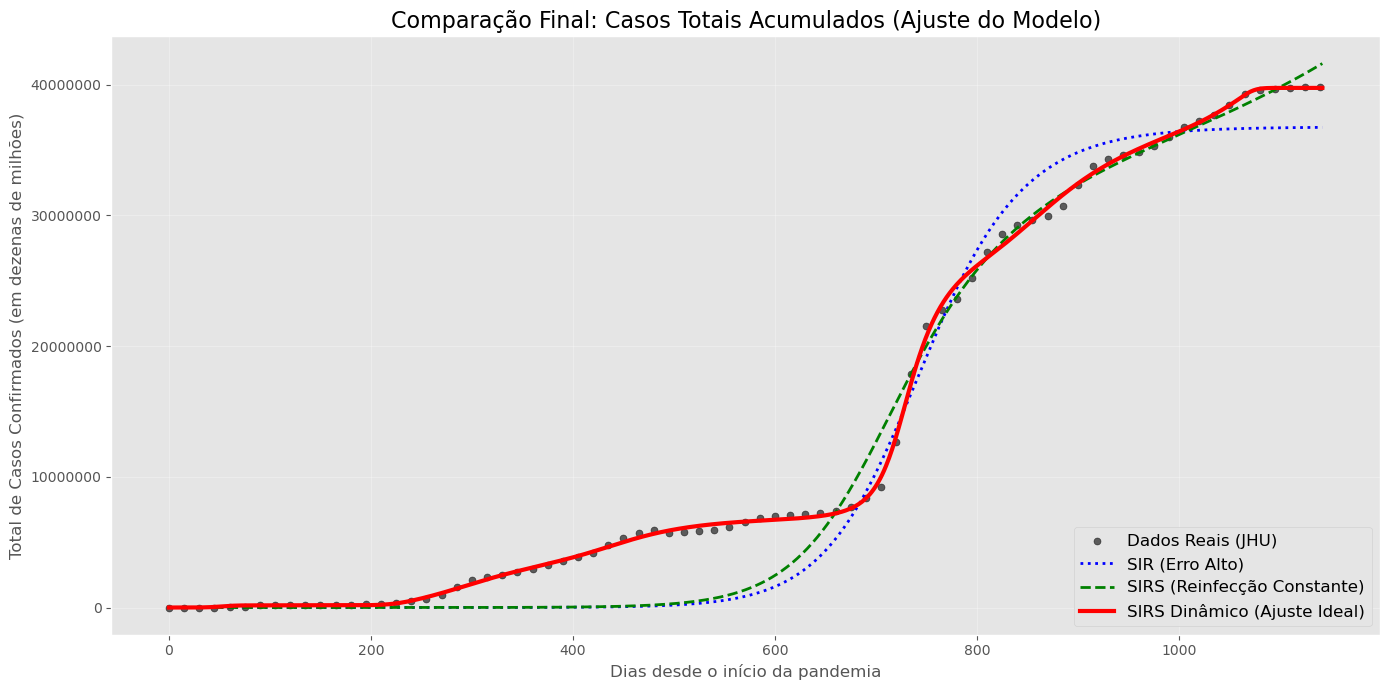

In [20]:
# Configuração da figura
plt.figure(figsize=(14, 7))
plt.title("Comparação Final: Casos Totais Acumulados (Ajuste do Modelo)", fontsize=16)

# 1. Dados Reais (Johns Hopkins)
# Usamos 'scatter' com pontos espaçados (::15) para o gráfico não ficar poluido
plt.scatter(x_days[::15], y_real_acc[::15], color='black', label='Dados Reais (JHU)', alpha=0.6, s=25)

# 2. Modelos (Curvas de Ajuste)
plt.plot(x_days, C_sir, label=f'SIR (Erro Alto)', linestyle=':', color='blue', linewidth=2)
plt.plot(x_days, C_sirs, label=f'SIRS (Reinfecção Constante)', linestyle='--', color='green', linewidth=2)
plt.plot(x_days, C_dyn, label=f'SIRS Dinâmico (Ajuste Ideal)', color='red', linewidth=3)

# Detalhes visuais
plt.ylabel("Total de Casos Confirmados (em dezenas de milhões)")
plt.xlabel("Dias desde o início da pandemia")
plt.legend(loc='lower right', fontsize=12)
plt.grid(True, alpha=0.3)

# Formatar eixo Y para não ficar em notação científica (opcional)
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

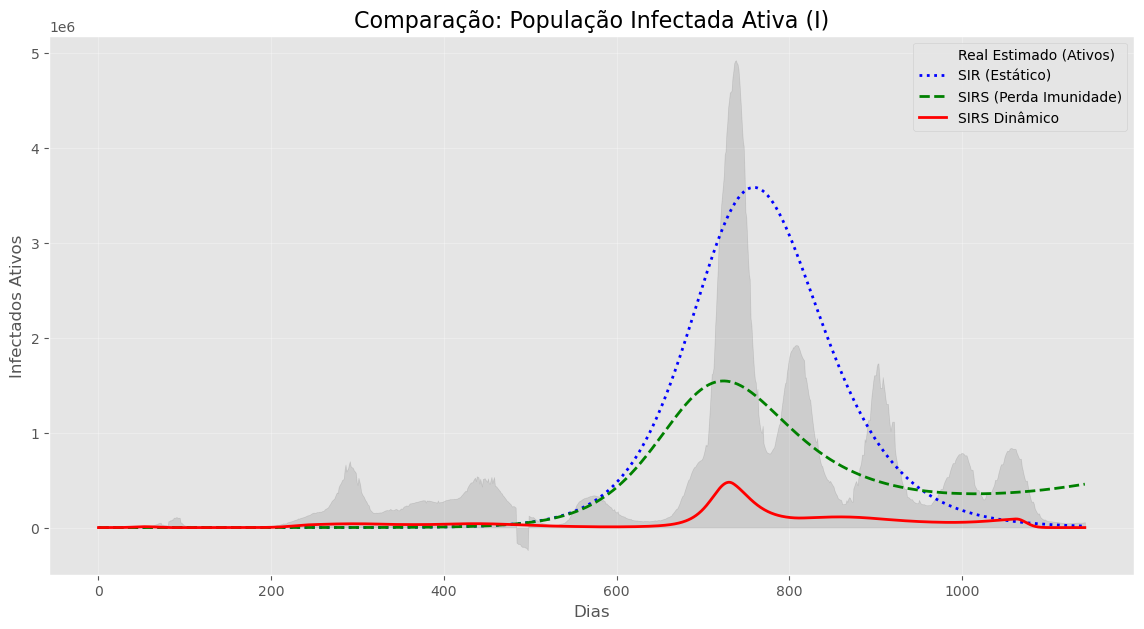

In [21]:
plt.figure(figsize=(14, 7))
plt.title("Comparação: População Infectada Ativa (I)", fontsize=16)

# Dados Reais (Estimativa)
plt.plot(x_days, y_real_active, color='black', alpha=0.3, label='Real Estimado (Ativos)', linewidth=0)
plt.fill_between(x_days, y_real_active, color='black', alpha=0.1)

# Modelos
plt.plot(x_days, I_sir, label='SIR (Estático)', linestyle=':', color='blue', linewidth=2)
plt.plot(x_days, I_sirs, label='SIRS (Perda Imunidade)', linestyle='--', color='green', linewidth=2)
plt.plot(x_days, I_dyn, label='SIRS Dinâmico', color='red', linewidth=2)

plt.xlabel("Dias")
plt.ylabel("Infectados Ativos")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

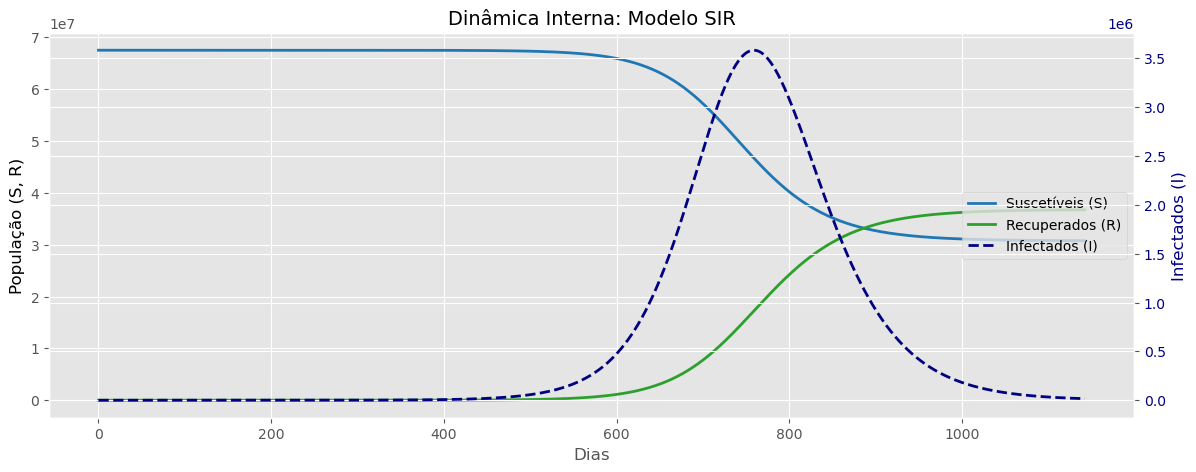

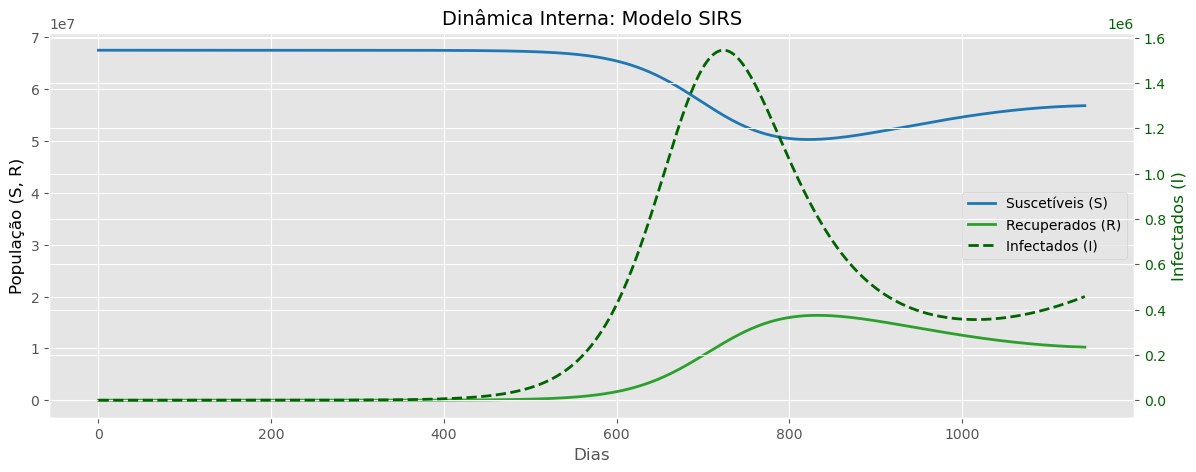

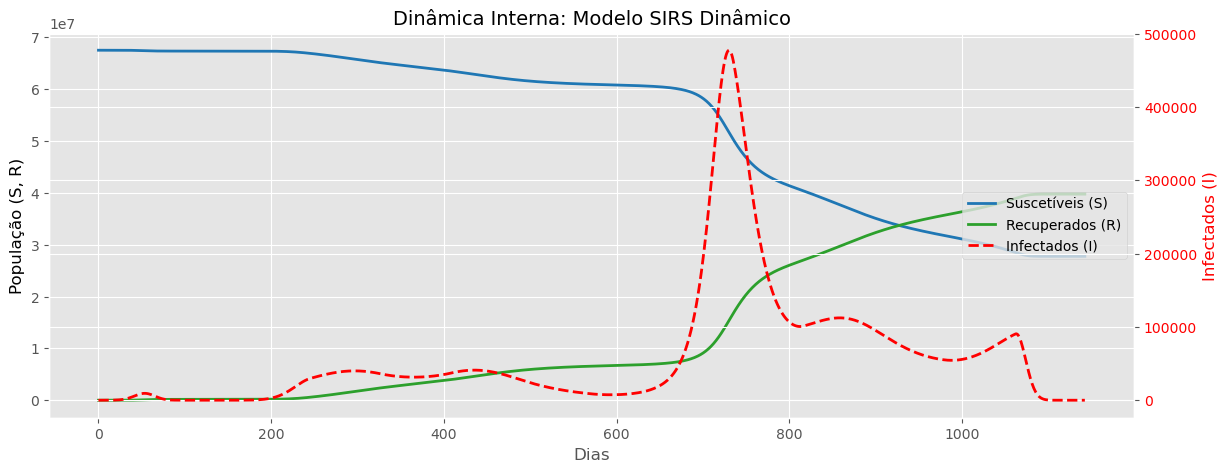

In [22]:
# Função única para plotar os gráficos de dinâmica (evita repetir código de plotagem)
def plot_dynamics(model_name, S, I, R, color_i):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax1.set_title(f"Dinâmica Interna: {model_name}", fontsize=14)
    
    # Eixo Esquerdo: S e R (Populações Grandes)
    ax1.set_xlabel("Dias")
    ax1.set_ylabel("População (S, R)", color='black')
    line1, = ax1.plot(x_days, S, label='Suscetíveis (S)', color='tab:blue', linewidth=2)
    line2, = ax1.plot(x_days, R, label='Recuperados (R)', color='tab:green', linewidth=2)
    
    # Eixo Direito: I (População Pequena - precisa de escala própria)
    ax2 = ax1.twinx()
    line3, = ax2.plot(x_days, I, label='Infectados (I)', color=color_i, linewidth=2, linestyle='--')
    ax2.set_ylabel("Infectados (I)", color=color_i)
    ax2.tick_params(axis='y', labelcolor=color_i)
    
    # Legenda Unificada
    lines = [line1, line2, line3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')
    
    plt.show()

# Gerar os 3 gráficos
plot_dynamics("Modelo SIR", S_sir, I_sir, R_sir, 'navy')
plot_dynamics("Modelo SIRS", S_sirs, I_sirs, R_sirs, 'darkgreen')
plot_dynamics("Modelo SIRS Dinâmico", S_dyn, I_dyn, R_dyn, 'red')